# ¡Hola Ariadna!

Mi nombre es Israel, estaré ayudándote a revisar este proyecto para que quede en su mejor versión.

Para simular la dinámica de un ambiente de trabajo, si veo algún error, en primer instancia solo los señalaré, dándote la oportunidad de encontrarlos y corregirlos por tu cuenta. Esto es útil para que te acostumbres a un escenario laboral. En caso de que no puedas resolver la tarea, te daré una información más precisa en la próxima revisión.

Encontrarás mis comentarios más abajo - **por favor, no los muevas, no los modifiques ni los borres**.

¿Cómo funciona esta revisión? Leeré atentamente tu código y te señalaré tus fortalezas y aquellas cosas que podemos mejorar. Los comentarios aparecerán de esta forma:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si todo está perfecto y no se requieren cambios en el código.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta. Se aceptan uno o dos comentarios de este tipo en el borrador, pero si hay más, deberás hacer las correcciones.
</div>

<div class="alert alert-block alert-danger">

<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si definitivamente hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma si algo no queda claro (copia este código en una celda markdown):

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class="tocSkip"></a>

Hola, muchas gracias por tus comentarios y la revisión.        
</div>

**Es un gusto acompañarte en este proceso, ¡empecemos!**

# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
from scipy import stats 
from statsmodels.stats.proportion import proportions_ztest
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [3]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


- El dataset no tiene valores ausentes .
- La columna date es de tipo object y debería ser datetime64. 

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [5]:
df['user_id'].unique()

array(['26f3052e-8500-44ea-8fff-06de65258abb',
       '92378c09-4bbf-40c7-945e-82b84f392d22',
       'a4397360-40e5-45d6-a7ff-dcb4da2c9a1f', ...,
       '02fbb5df-c7a7-4286-a8bc-97bd741fa2d7',
       '299ad979-d990-458f-81a8-b9fd21a023b0',
       'fabb98e7-0f74-4baf-9a32-ac8e09936787'], dtype=object)

 **Variable `date`**  
Explorar rango de fechas

In [6]:
df["date"] = pd.to_datetime(df['date'])

In [7]:
df["date"].dtype

dtype('<M8[ns]')

In [8]:
# Resumen estadístico
df["date"].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [9]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [10]:
# Resumen estadístico
df['gasto'].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [11]:
# Resumen estadístico de usuarios que se convirtieron
df['converted'].describe()

count    40000.00000
mean         0.14265
std          0.34972
min          0.00000
25%          0.00000
50%          0.00000
75%          0.00000
max          1.00000
Name: converted, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [12]:
# Explorar variables categóricas y cómo se distribuyen
col_categoricas = ['landing', 'region', 'dispositivo', 'traffic_source', 'user_type']

for col in col_categoricas:
    print("\nConteo de categorías:")
    print(df[col].value_counts())


Conteo de categorías:
B    20018
A    19982
Name: landing, dtype: int64

Conteo de categorías:
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

Conteo de categorías:
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

Conteo de categorías:
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

Conteo de categorías:
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


- Todas las columnas tienen valores esperados.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. Conviertes `date` a `datetime`, validas correctamente el rango temporal y obtienes el resumen general de `gasto`. Sin embargo, hay dos validaciones incompletas. Primero, `df['user_id'].unique()` solo muestra los identificadores, pero no comprueba explícitamente que existan 40,000 usuarios únicos ni que haya 0 duplicados. Segundo, en la sección “Resumen estadístico de usuarios que se convirtieron” ejecutas `df['converted'].describe()` en lugar de `df[df['converted']==1]['gasto'].describe()`

</div>


## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [13]:
# Gasto por versión
gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto']
gasto_B = df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto']

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

### Prueba 

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe una diferencia significativa en el gasto promedio por usuario convertido entre la página A y la página B
- **Hipótesis alternativa (H₁):** Existe una diferencia significativa en el gasto promedio por usuario convertido entre la página A y la página B

In [14]:
# Aplicar prueba
stats.ttest_ind(gasto_A, gasto_B)
t_stat, p_value = stats.ttest_ind(gasto_A, gasto_B)

# Visualizar resultados
print(f"Estadístico : {t_stat}")
print(f"Valor p: {p_value}")

Estadístico : -9.36563589591332
Valor p: 1.0635288333792346e-20


In [15]:
# Gasto promedio por usuario en cada versión
print("Promedio Página A:", gasto_A.mean())
print("Promedio Página B:", gasto_B.mean())

Promedio Página A: 61.0865724522293
Promedio Página B: 68.74536005009392


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula ($H_0$), ya que el valor p ($1.06 \times 10^{-20}$) es drásticamente menor al nivel de p ≤ 0.05.

**Interpretación de negocio:**  
- Evidencia: Existe evidencia estadística suficiente (valor p prácticamente nulo) para afirmar que la diferencia en el gasto promedio no es producto del azar.

- Dirección: Los promedios indican que la diferencia es favorable a la versión B, la cual genera un gasto promedio significativamente mayor por usuario convertido en comparación con la versión A.

- Limitaciones: Es importante considerar que este resultado se basa en una muestra de usuarios recolectada durante el periodo del experimento.

- Se recomienda implementar la Versión B de manera definitiva para el 100% de los usuarios, ya que demostró ser estadísticamente superior en la generación de ingresos por cliente convertido (68.74 vs 61.09 de la Versión A).

---

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. Filtras correctamente a los usuarios convertidos. Sin embargo, ejecutas `stats.ttest_ind(gasto_A, gasto_B)` con `equal_var=True` por defecto y no aplicas Levene

</div>



## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe una diferencia significativa en la tasa de conversión entre la página A y la página B.  
- **Hipótesis alternativa (H₁):** Existe una diferencia significativa en la tasa de conversión entre la página A y la página B.

In [16]:
# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()

# Total de usuarios por página
totales = df.groupby('landing')['converted'].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [17]:
# Pasar valores a formato de lista
exitosos = [conversiones['A'], conversiones['B']]
total = [totales['A'], totales['B']]

In [18]:
# Porcentajes de conversión 
pct_A = (exitosos[0] / total[0]) * 100
pct_B = (exitosos[1] / total[1]) * 100

print(f"Página A: {pct_A:.2f}%")
print(f"Página B: {pct_B:.2f}%")

Página A: 12.57%
Página B: 15.96%


In [19]:
# Aplicar prueba
z_stat, p_value = proportions_ztest(exitosos, total)


# Visualizar resultados
print(f"Estadístico : {z_stat}")
print(f"Valor p: {p_value}")

Estadístico : -9.677362674655983
Valor p: 3.7629765627523803e-22


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula, ya que el valor p ($3.76 \times 10^{-22}$) es drásticamente menor al nivel de significancia (alpha = 0.05).

**Interpretación de negocio:**  
- Evidencia: Existe evidencia estadística suficiente para afirmar que la diferencia en la tasa de conversión entre ambas versiones no es producto del azar.
- Dirección: La diferencia es favorable a la Página B, la cual presenta una tasa de conversión superior (15.96% vs 12.57% de la Página A).
- Limitaciones: Los resultados provienen de una muestra de usuarios durante el periodo de prueba.

Se recomienda implementar la **Página B** para el total de los usuarios, ya que incrementa de forma estadísticamente significativa la proporción de usuarios que realizan una conversión (15.96% frente al 12.57% de la versión A)

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Excelente trabajo. Calculas correctamente lo requerido, aplicas `proportions_ztest`
</div>


## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe una asociación significativa entre la fuente de tráfico (traffic_source) y la conversión (converted), las variables son independientes.
- **Hipótesis alternativa (H₁):** Existe una asociación significativa entre la fuente de tráfico (traffic_source) y la conversión (converted), las variables no son independientes.

In [20]:
# Tabla de contingencia para prueba chi2
tabla = pd.crosstab(df['traffic_source'], df['converted'])
tabla

converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


In [21]:
# Aplicar prueba
stats.chi2_contingency(tabla)
chi2_stat, p_value, dof, expected = stats.chi2_contingency(tabla)
print(f"Estadístico Chi2: {chi2_stat:.3f}")
print(f"Valor p: {p_value:.3f}")
print(f"Grados de libertad:{dof}")
print("/nFrecuencias esperadas:")
print(expected)

Estadístico Chi2: 8.662
Valor p: 0.034
Grados de libertad:3
/nFrecuencias esperadas:
[[10232.47225  1702.52775]
 [ 5249.55405   873.44595]
 [15421.15445  2565.84555]
 [ 3390.81925   564.18075]]


In [22]:
# Tabla de contingencia normalizada
pd.crosstab(df['traffic_source'], df['converted'], normalize='index')*100

converted,0,1
traffic_source,,
Ads,85.261835,14.738165
Email,85.007349,14.992651
Organic,86.212264,13.787736
Referral,86.118837,13.881163


### 📝 Conclusión e interpretación

**Decisión:**  
(¿Se rechaza o no la hipótesis nula?)

**Interpretación de negocio:**  
Explica qué indican los resultados considerando tanto las cantidades absolutas como las tasas de conversión.


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. La tabla absoluta, la tabla normalizada y la prueba chi-cuadrada están correctamente calculadas. Sin embargo, la sección de conclusión e interpretación quedó completamente sin responder.

</div>


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe una asociación significativa entre el tipo de usuario y la conversión.
- **Hipótesis alternativa (H₁):** Existe una asociación significativa entre el tipo de usuario y la conversión. 

In [23]:
# Tabla de contingencia para prueba chi2
tabla = pd.crosstab(df['user_type'], df['converted'])
tabla

converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [24]:
# Aplicar prueba
stats.chi2_contingency(tabla)
chi2_stat, p_value, dof, expected = stats.chi2_contingency(tabla)
print(f"Estadístico Chi2: {chi2_stat:.3f}")
print(f"Valor p: {p_value:.3f}")
print(f"Grados de libertad:{dof}")
print("/nFrecuencias esperadas:")
print(expected)


Estadístico Chi2: 0.513
Valor p: 0.474
Grados de libertad:1
/nFrecuencias esperadas:
[[22319.39255  3713.60745]
 [11974.60745  1992.39255]]


In [25]:
# Tabla de contingencia normalizada
pd.crosstab(df['user_type'], df['converted'], normalize='index')*100

converted,0,1
user_type,,
Nuevo,85.641301,14.358699
Recurrente,85.909644,14.090356


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipótesis nula, ya que el valor p (0.474) es significativamente mayor que el nivel de significancia alpha = 0.05.

**Interpretación de negocio:**  
- Evidencia: No existe evidencia estadística suficiente para afirmar que el tipo de usuario (user_type) influye en la probabilidad de conversión (converted). La pequeña variación observada se debe al azar.
- Dirección: Al revisar los porcentajes, los usuarios nuevos convierten al 14.36% y los recurrentes al 14.09%. Esta diferencia de solo 0.27% no representa un cambio real en el comportamiento de ambos grupos.
- Limitaciones y recomendación: La prueba demuestra que ser usuario nuevo o recurrente no cambia el rendimiento del proceso de conversión. Por lo tanto, no es necesario crear estrategias diferenciadas o personalizadas por tipo de usuario para esta prueba.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. La tabla absoluta, la tabla normalizada y la prueba chi-cuadrada para `user_type` son correctas.

</div>


## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

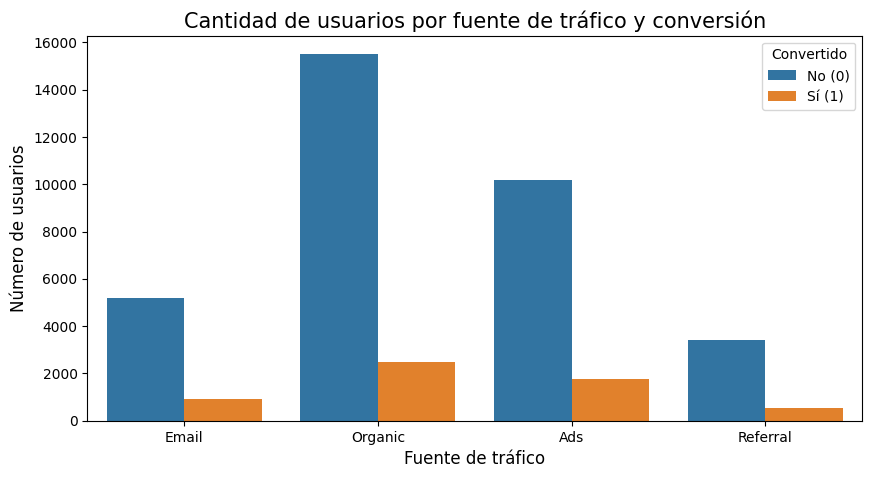

In [32]:
# Grafico de barras agrupadas 
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='traffic_source', hue='converted')
plt.title('Cantidad de usuarios por fuente de tráfico y conversión', fontsize=15)
plt.xlabel('Fuente de tráfico', fontsize=12)
plt.ylabel('Número de usuarios',fontsize=12)
plt.legend(title='Convertido', labels=['No (0)', 'Sí (1)'])
plt.show()

**Interpretación del gráfico:**
- **Volumen de tráfico:** La mayor cantidad de usuarios proviene de Organic y Ads, seguidos por Email y finalmente Referral.
- **Comportamiento de conversión:** En todos los canales, la gran mayoría de los usuarios no convierte (barras azules). Sin embargo, Organic y Ads concentran el mayor número absoluto de usuarios convertidos (barras naranjas) simplemente porque traen mucho más volumen de tráfico en general.

### Relación entre el tipo de usuario y la conversión

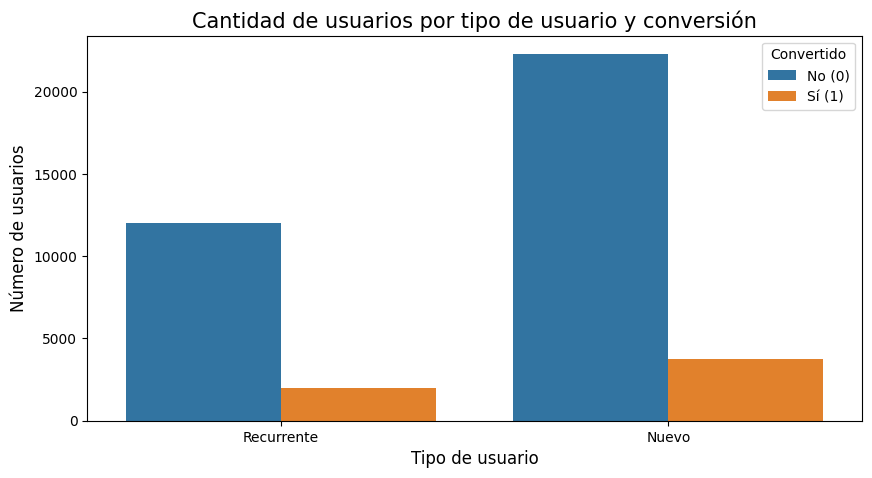

In [33]:
# Grafico de barras agrupadas 
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='user_type', hue='converted')
plt.title('Cantidad de usuarios por tipo de usuario y conversión', fontsize=15)
plt.xlabel('Tipo de usuario', fontsize=12)
plt.ylabel('Número de usuarios',fontsize=12)
plt.legend(title='Convertido', labels=['No (0)', 'Sí (1)'])
plt.show()

**Interpretación del gráfico:**
- **Volumen:** Los usuarios nuevos* representan un volumen total considerablemente mayor que los usuarios recurrentes.
- **Proporción de conversión:** La relación entre los usuarios que no convierten (barras azules) y los que sí convierten (barras naranjas) se mantiene visualmente idéntica en ambos grupos. Esto confirma visualmente el resultado del test Chi-cuadrado: no hay diferencia en la probabilidad de conversión según el tipo de usuario.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. Sin embargo, solo están presentes 2 de las 4 visualizaciones requeridas

</div>


## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- Observacion 1: El gasto promedio por usuario convertido en la Página A fue de 61.09,mientras que en la Página B ascendió a 68.75.
- Observacion 2: La prueba t arrojó un valor p extremadamente bajo ($1.06 \times 10^{-20}$), confirmando que la diferencia de gasto es estadísticamente significativa.
- **Interpretación:**
  La Página B no solo atrae conversiones, sino que logra que cada usuario que convierte genere más valor económico/ingresos en comparación con la Página A.
<br>

**Tasa de conversión:** 
- Observación 1: La tasa de conversión de la Página B es del 15.96%, frente al 12.57% obtenido por la Página A.
- Observación 2: La prueba Z para dos proporciones mostró una diferencia estadísticamente significativa a favor de la Página B (p < 0.05).
- **Interpretación:** La Página B supera a la A en efectividad general, logrando convertir a una mayor proporción de visitantes totales. Por lo tanto, la Página B es la opción ganadora en ambos métricos clave (efectividad de conversión y valor promedio por cliente).

---

#### 📊 **Segmentación por fuente de tráfico**
- Observación: Email (14.99%) y Ads (14.74%) presentan las tasas de conversión más altas, superando a Referral (13.88%) y Organic (13.79%). La prueba Chi-cuadrado confirmó que esta asociación es estadísticamente significativa (p = 0.034).
- **Interpretación:** Aunque el mayor volumen absoluto de usuarios proviene de tráfico orgánico, los canales pagados/directos (Email y Ads) son más eficientes convirtiendo visitantes en clientes.
 
 ---

#### 📊 **Segmentación por tipo de usuario**
- Observación: Los usuarios nuevos convirtieron al 14.36% y los recurrentes al 14.09%. La prueba Chi-cuadrado arrojó un valor p de 0.474.
- **Interpretación:** La diferencia entre ambos grupos es insignificante (0.27%) y no es estadísticamente relevante. El comportamiento de conversión es prácticamente idéntico sin importar si el usuario es nuevo o recurrente.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:** 
1. Implementar la Página B: Desplegar la Página B de forma definitiva para el 100% de los usuarios, ya que genera una mayor tasa de conversión (15.96% vs 12.57%) y un mayor gasto promedio por cliente (68.74 vs 61.09).
2. Mantener una estrategia unificada de usuario: No invertir recursos en personalizar la experiencia según el tipo de usuario (nuevos vs. recurrentes), ya que ambos responden exactamente igual.